# Optimization Algorithms

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/caam37830-sci-comp/notes/blob/main/03_optimization/optimization_algorithms.ipynb)

[Optimization in SciPy](scipy_opt.ipynb) showed how to call `scipy.optimize.minimize`.
This section looks at the algorithms behind the `method=` argument: why one method takes
ten iterations where another takes ten thousand, and which one to reach for.

We minimize a smooth function $f : \mathbb R^n \to \mathbb R$ without constraints.  Almost
every method has the form

$$ x_{k+1} = x_k + \alpha_k p_k, $$

a **search direction** $p_k$ and a **step length** $\alpha_k$.  The methods differ in how
they choose the two.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize, least_squares, rosen, rosen_der, rosen_hess

rng = np.random.default_rng(37830)

## Gradient descent

The simplest choice of direction is the steepest one, $p_k = -\nabla f(x_k)$.

### Quadratics and the condition number

Everything important about gradient descent already shows up on a quadratic

$$ f(x) = \tfrac12 x^\top A x - b^\top x, \qquad A \text{ symmetric positive definite}, $$

whose minimizer solves $Ax = b$ (so minimizing $f$ is one way to solve a linear system;
compare [Dense Linear Algebra](../02_linear_algebra/numpy_scipy_linalg.ipynb)).  The
gradient is $Ax - b$, and with a fixed step $\alpha$ the error $e_k = x_k - x^*$ satisfies

$$ e_{k+1} = (I - \alpha A)\, e_k . $$

In the eigenbasis of $A$, the component along an eigenvalue $\lambda$ is multiplied by
$1 - \alpha\lambda$ at each step.  Write $L$ and $\mu$ for the largest and smallest
eigenvalues.  The iteration converges only if $\alpha < 2/L$, and with $\alpha = 1/L$ the
slowest component shrinks by $1 - \mu/L = 1 - 1/\kappa$ per step, where
$\kappa = L/\mu$ is the condition number.  Gradient descent needs about
$\kappa \log(1/\varepsilon)$ iterations to reduce the error by a factor $\varepsilon$.

The picture: the level sets of an ill-conditioned quadratic are long thin ellipses, and the
negative gradient points mostly across the valley instead of along it.

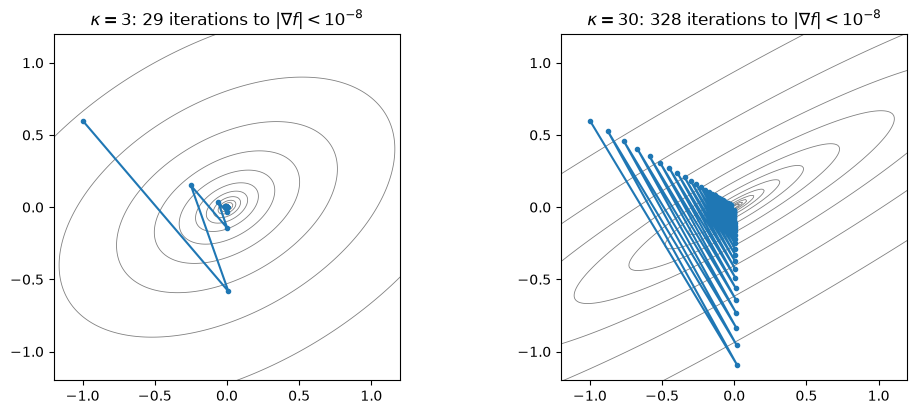

In [2]:
def quadratic(kappa, angle=np.pi / 6):
    """
    SPD matrix with eigenvalues 1 and kappa, eigenvectors rotated by angle
    """
    c, s = np.cos(angle), np.sin(angle)
    Q = np.array([[c, -s], [s, c]])
    return Q @ np.diag([1.0, kappa]) @ Q.T


def gd_fixed(A, x0, alpha, tol=1e-8, maxit=200_000):
    """
    gradient descent on f = x^T A x / 2 with a fixed step; returns the iterates
    """
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    for _ in range(maxit):
        g = A @ x
        if np.linalg.norm(g) < tol:
            break
        x = x - alpha * g
        path.append(x.copy())
    return np.array(path)


fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 200), np.linspace(-1.2, 1.2, 200))
for a, kappa in zip(ax, [3, 30]):
    A = quadratic(kappa)
    F = 0.5 * (A[0, 0] * xx**2 + 2 * A[0, 1] * xx * yy + A[1, 1] * yy**2)
    path = gd_fixed(A, [-1.0, 0.6], alpha=2 / (1 + kappa))   # the best fixed step
    a.contour(xx, yy, F, levels=np.logspace(-3, 1, 12), colors='gray', linewidths=0.6)
    a.plot(path[:60, 0], path[:60, 1], 'o-', ms=3)
    a.set_aspect('equal')
    a.set_title(f'$\\kappa = {kappa}$: {len(path) - 1} iterations to $|\\nabla f| < 10^{{-8}}$')
plt.show()

The iterates bounce from one wall of the valley to the other while creeping along it.  The
number of iterations grows in proportion to $\kappa$:

In [3]:
print(f"{'kappa':>7} {'step 1/L':>10} {'step 2/(L+mu)':>14}")
for kappa in [10, 100, 1000, 10000]:
    A = quadratic(kappa)
    n1 = len(gd_fixed(A, [1.0, 1.0], alpha=1 / kappa)) - 1
    n2 = len(gd_fixed(A, [1.0, 1.0], alpha=2 / (1 + kappa))) - 1
    print(f"{kappa:7d} {n1:10d} {n2:14d}")

  kappa   step 1/L  step 2/(L+mu)
     10        178             99
    100       1864           1102
   1000      18724          12162


  10000     187317         133130


### Line search

For a general $f$ we don't know $L$, and a good step size changes from place to place.  A
**backtracking line search** starts with a full step $\alpha = 1$ and halves it until the
step gives a *sufficient decrease*

$$ f(x_k + \alpha p_k) \le f(x_k) + c\,\alpha\, \nabla f(x_k)^\top p_k, $$

with a small constant like $c = 10^{-4}$ (the **Armijo condition**).  This rules out steps
that reduce $f$ by only a negligible amount, and it works with any descent direction
$p_k$, which we will reuse below.

In [4]:
def backtracking(f, grad, x, p, alpha=1.0, c=1e-4, shrink=0.5):
    """
    largest alpha in {1, 1/2, 1/4, ...} satisfying the Armijo condition
    """
    fx, slope = f(x), grad(x) @ p
    while f(x + alpha * p) > fx + c * alpha * slope:
        alpha *= shrink
    return alpha


def gradient_descent(f, grad, x0, tol=1e-6, maxit=100_000):
    """
    gradient descent with backtracking; returns the array of iterates
    """
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    for _ in range(maxit):
        g = grad(x)
        if np.linalg.norm(g) < tol:
            break
        x = x - backtracking(f, grad, x, -g) * g
        path.append(x.copy())
    return np.array(path)

The standard hard test is **Rosenbrock's function**
$f(x, y) = (1 - x)^2 + 100\,(y - x^2)^2$, whose minimum at $(1, 1)$ sits at the bottom
of a long, curved, flat-bottomed valley.  SciPy provides it as `rosen`, with gradient
`rosen_der` and Hessian `rosen_hess`.

In [5]:
x0 = np.array([-1.2, 1.0])
start = time.perf_counter()
path_gd = gradient_descent(rosen, rosen_der, x0)
print(f"gradient descent: {len(path_gd) - 1} iterations, {time.perf_counter() - start:.1f} s, "
      f"final point {path_gd[-1]}")

gradient descent: 13756 iterations, 1.3 s, final point [0.99999922 0.99999843]


More than ten thousand iterations for a two-variable problem.  Near the minimum the Hessian
of the Rosenbrock function has condition number around 2500, so this is the quadratic
picture all over again.

## Momentum

A cheap and remarkably effective fix is to remember the previous step.
**Nesterov's accelerated gradient** method takes

$$
x_{k+1} = y_k - \tfrac{1}{L}\nabla f(y_k), \qquad
y_{k+1} = x_{k+1} + \beta\,(x_{k+1} - x_k), \qquad
\beta = \frac{\sqrt\kappa - 1}{\sqrt\kappa + 1}.
$$

The extra term keeps pushing in the direction the iterates have been moving, which builds
up speed along the valley floor and damps the bouncing across it.  On a quadratic the
iteration count drops from $O(\kappa)$ to $O(\sqrt\kappa)$.

In [6]:
def nesterov(A, x0, tol=1e-8, maxit=200_000):
    """
    Nesterov's method on f = x^T A x / 2; returns the number of iterations
    """
    lam = np.linalg.eigvalsh(A)
    L, kappa = lam.max(), lam.max() / lam.min()
    beta = (np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)
    x = y = np.array(x0, dtype=float)
    for k in range(maxit):
        x_new = y - (A @ y) / L
        y = x_new + beta * (x_new - x)
        x = x_new
        if np.linalg.norm(A @ x) < tol:
            return k + 1
    return maxit


print(f"{'kappa':>7} {'gradient descent':>17} {'Nesterov':>9}")
for kappa in [10, 100, 1000, 10000]:
    A = quadratic(kappa)
    n_gd = len(gd_fixed(A, [1.0, 1.0], alpha=1 / kappa)) - 1
    print(f"{kappa:7d} {n_gd:17d} {nesterov(A, [1.0, 1.0]):9d}")

  kappa  gradient descent  Nesterov
     10               178        58
    100              1864       208
   1000             18724       680


  10000            187317      2175


Momentum is the reason the optimizers used to train neural networks (SGD with momentum,
Adam) work as well as they do; see [PyTorch Neural Networks](../08_data/pytorch.ipynb).

## Newton's method

Newton's method uses second derivatives.  Near $x_k$,

$$ f(x_k + p) \approx f(x_k) + \nabla f(x_k)^\top p + \tfrac12\, p^\top H(x_k)\, p, $$

where $H$ is the Hessian matrix.  If $H$ is positive definite, this quadratic model is
minimized by the solution of

$$ H(x_k)\, p_k = -\nabla f(x_k), $$

which is the Newton step.  Solve the linear system; don't form $H^{-1}$.  This is the
same Newton's method as for root finding in [Root Finding](../04_functions/roots.ipynb),
applied to the equation $\nabla f = 0$.

On a quadratic, the model is exact, so Newton's method converges in one step whatever the
condition number.  More generally, Newton's method is *affine invariant*: a linear change of
variables does not change its iterates, so ill-conditioning of this kind cannot slow it
down.  Near a minimum where $H$ is positive definite the convergence is quadratic, which
roughly doubles the number of correct digits per step (see
[Convergence of Algorithms](../01_analysis/convergence.ipynb)).

Far from the minimum the Hessian may not be positive definite, and then the Newton step
need not go downhill.  Practical versions combine it with a line search, falling back on
the gradient direction when necessary, or use a **trust region**, which only trusts the
quadratic model within a radius that grows and shrinks with its success.

In [7]:
def newton(f, grad, hess, x0, tol=1e-10, maxit=100):
    """
    Newton's method with backtracking; uses -grad when the Newton step points uphill
    """
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    for _ in range(maxit):
        g = grad(x)
        if np.linalg.norm(g) < tol:
            break
        p = np.linalg.solve(hess(x), -g)
        if g @ p >= 0:                   # not a descent direction
            p = -g
        x = x + backtracking(f, grad, x, p) * p
        path.append(x.copy())
    return np.array(path)


path_newton = newton(rosen, rosen_der, rosen_hess, x0)
err = np.linalg.norm(path_newton - 1, axis=1)
print(f"Newton: {len(path_newton) - 1} iterations")
print("distance to the minimum over the last iterations:", np.array2string(err[-6:], precision=1))

Newton: 22 iterations
distance to the minimum over the last iterations: [7.1e-02 9.2e-03 1.2e-03 2.7e-06 1.4e-10 0.0e+00]


Twenty-odd iterations instead of thirteen thousand, and the last few show the quadratic
convergence: $10^{-2}, 10^{-3}, 10^{-6}, 10^{-10}$, then zero to machine precision.

The cost is the Hessian.  It has $n^2$ entries to compute and store, and each step solves an
$n \times n$ system, $O(n^3)$ work for a dense matrix.  For large $n$ that is often out of
the question.

## Quasi-Newton methods: BFGS

**Quasi-Newton** methods build up an approximation to the Hessian, or to its inverse, from
the gradients they have already computed.  After a step $s_k = x_{k+1} - x_k$ the gradient
changes by $y_k = \nabla f(x_{k+1}) - \nabla f(x_k) \approx H s_k$.  The **BFGS** method
updates an approximation $B_k \approx H^{-1}$ so that it satisfies $B_{k+1} y_k = s_k$
exactly while changing as little as possible:

$$
B_{k+1} = (I - \rho_k s_k y_k^\top)\, B_k\, (I - \rho_k y_k s_k^\top) + \rho_k s_k s_k^\top,
\qquad \rho_k = \frac{1}{y_k^\top s_k}.
$$

Each iteration costs $O(n^2)$ and needs only gradients, and the convergence is
superlinear.  **L-BFGS** stores only the last few pairs $(s_k, y_k)$ instead of the
matrix, so it needs $O(n)$ memory and scales to millions of variables.

BFGS: 35 iterations, final point [1. 1.]


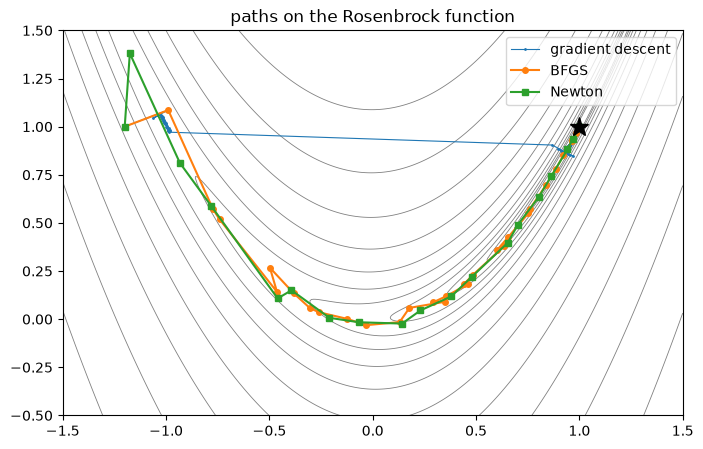

In [8]:
def bfgs(f, grad, x0, tol=1e-8, maxit=1000):
    """
    BFGS with backtracking; returns the array of iterates
    """
    x = np.array(x0, dtype=float)
    I = np.eye(len(x))
    B = np.eye(len(x))                   # approximate inverse Hessian
    g = grad(x)
    path = [x.copy()]
    for _ in range(maxit):
        if np.linalg.norm(g) < tol:
            break
        p = -B @ g
        s = backtracking(f, grad, x, p) * p
        x_new = x + s
        g_new = grad(x_new)
        y = g_new - g
        if y @ s > 1e-12:                # skip the update if the curvature is not positive
            rho = 1 / (y @ s)
            B = (I - rho * np.outer(s, y)) @ B @ (I - rho * np.outer(y, s)) + rho * np.outer(s, s)
        x, g = x_new, g_new
        path.append(x.copy())
    return np.array(path)


path_bfgs = bfgs(rosen, rosen_der, x0)
print(f"BFGS: {len(path_bfgs) - 1} iterations, final point {path_bfgs[-1]}")

xx, yy = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-0.5, 1.5, 300))
F = rosen(np.array([xx, yy]))
plt.figure(figsize=(8, 5))
plt.contour(xx, yy, F, levels=np.logspace(-1, 3, 14), colors='gray', linewidths=0.6)
plt.plot(path_gd[:, 0], path_gd[:, 1], '.-', ms=2, lw=0.8, label='gradient descent')
plt.plot(path_bfgs[:, 0], path_bfgs[:, 1], 'o-', ms=4, label='BFGS')
plt.plot(path_newton[:, 0], path_newton[:, 1], 's-', ms=4, label='Newton')
plt.plot(1, 1, 'k*', ms=14)
plt.legend()
plt.title('paths on the Rosenbrock function')
plt.show()

Gradient descent bounces around near the start, gets across in one long step that the line
search happens to accept, and then spends thousands of iterations crawling along the
valley floor.  Newton and BFGS follow the valley around to the minimum.

SciPy implements all of these and more.  Here is the same problem with several `method`
options, counting iterations (`nit`) and evaluations of $f$ (`nfev`).

In [9]:
print(f"{'method':12} {'nit':>5} {'nfev':>5}  {'distance to (1, 1)':>18}")
for method in ["Nelder-Mead", "CG", "BFGS", "L-BFGS-B", "Newton-CG", "trust-exact"]:
    options = {}
    if method != "Nelder-Mead":
        options["jac"] = rosen_der
    if method in ("Newton-CG", "trust-exact"):
        options["hess"] = rosen_hess
    res = minimize(rosen, x0, method=method, **options)
    print(f"{method:12} {res.nit:5d} {res.nfev:5d}  {np.linalg.norm(res.x - 1):18.1e}")

method         nit  nfev  distance to (1, 1)
Nelder-Mead     85   159             4.8e-05
CG              36    78             6.1e-09
BFGS            32    39             6.1e-08
L-BFGS-B        36    44             2.2e-06
Newton-CG       83   105             3.9e-05
trust-exact     25    26             1.3e-09


`Nelder-Mead` uses no derivatives at all, which is convenient but scales poorly with the
dimension.  `CG` is the nonlinear conjugate gradient method, which needs only $O(n)$
memory.  `trust-exact` is a trust-region Newton method.  The defaults in `minimize` are
`BFGS` for unconstrained problems and `L-BFGS-B` when there are bounds.

## Nonlinear least squares

Fitting a model to data usually means minimizing a sum of squares,

$$ \min_\theta\ \tfrac12 \|r(\theta)\|^2, \qquad r_i(\theta) = \text{model}_i(\theta) - \text{data}_i . $$

The gradient is $J^\top r$, where $J$ is the Jacobian of the residuals, and the Hessian is
$J^\top J + \sum_i r_i \nabla^2 r_i$.  When the model fits well the residuals are small and
the second term can be dropped.  The resulting **Gauss-Newton** step solves the linear
least squares problem

$$ \min_p\ \|J p + r\|^2, $$

best solved with QR or `lstsq` rather than the normal equations (see the least squares
discussion in [Dense Linear Algebra](../02_linear_algebra/numpy_scipy_linalg.ipynb)).  No
second derivatives are needed.

In [10]:
def gauss_newton(r, jac, theta0, tol=1e-12, maxit=50):
    """
    Gauss-Newton iteration for min ||r(theta)||^2; returns the iterates
    """
    theta = np.array(theta0, dtype=float)
    path = [theta.copy()]
    for _ in range(maxit):
        p, *_ = np.linalg.lstsq(jac(theta), -r(theta), rcond=None)
        theta = theta + p
        path.append(theta.copy())
        if np.linalg.norm(p) <= tol * (1 + np.linalg.norm(theta)):
            break
    return np.array(path)


# noisy samples of a decaying exponential a * exp(-b t)
t = np.linspace(0, 4, 40)
y = 2.0 * np.exp(-1.3 * t) + 0.02 * rng.standard_normal(t.size)

r = lambda th: th[0] * np.exp(-th[1] * t) - y
jac = lambda th: np.column_stack([np.exp(-th[1] * t), -th[0] * t * np.exp(-th[1] * t)])

path = gauss_newton(r, jac, [1.0, 1.0])
print("Gauss-Newton from (1, 1):")
for k, th in enumerate(path):
    print(f"  step {k}: a = {th[0]:.10f}, b = {th[1]:.10f}")

Gauss-Newton from (1, 1):
  step 0: a = 1.0000000000, b = 1.0000000000
  step 1: a = 1.9706222412, b = 1.4485784026
  step 2: a = 1.9961166722, b = 1.2774367340
  step 3: a = 1.9992013305, b = 1.2938834802
  step 4: a = 1.9994263011, b = 1.2942968236
  step 5: a = 1.9994303200, b = 1.2943028039
  step 6: a = 1.9994303775, b = 1.2943028893
  step 7: a = 1.9994303783, b = 1.2943028905
  step 8: a = 1.9994303784, b = 1.2943028905
  step 9: a = 1.9994303784, b = 1.2943028905


The correction shrinks by a roughly constant factor each step: fast **linear**
convergence.
Gauss-Newton is quadratically convergent only when the residual at the solution is zero;
with noisy data it is linear, with a rate that is good when the noise is small.

From a poor starting point, plain Gauss-Newton can run away:

In [11]:
print("Gauss-Newton from (1, 5):", gauss_newton(r, jac, [1.0, 5.0])[-1])
print("Levenberg-Marquardt from (1, 5):", least_squares(r, [1.0, 5.0], jac=jac, method='lm').x)

Gauss-Newton from (1, 5): [ 3.65564306e-22 -1.14398880e+01]
Levenberg-Marquardt from (1, 5): [1.99943032 1.2943028 ]


The **Levenberg-Marquardt** method damps the step,

$$ (J^\top J + \lambda I)\, p = -J^\top r, $$

and adjusts $\lambda$ as it goes.  A large $\lambda$ gives a short step in the gradient
direction; a small one gives the Gauss-Newton step.  It is what `least_squares(...,
method='lm')` uses; the default `method='trf'` is a trust-region relative that also
handles bounds.  `scipy.optimize.curve_fit` wraps the same machinery for the common case
`y = model(x, *params)`.

### Example: fitting an ODE model

In [Initial Value Problems](../05_differential_equations/ode_initial.ipynb) you modeled
lions and zebras with a predator-prey system.  Suppose you have instead counted the animals
every 10 months, with 5% counting errors, and want to recover the rates
$\alpha, \beta, \gamma$.  The residual function solves the ODE for the trial parameters,
so every evaluation of $r$ is a call to `solve_ivp`.

In [12]:
def lions_zebras(t, y, alpha, beta, gamma):
    lions, zebras = y
    return [-gamma * lions + beta / 500 * lions * zebras,
            alpha * zebras - beta / 100 * lions * zebras]


true_params = np.array([0.02, 0.3, 0.02])
y0 = [5.0, 50.0]
t_obs = np.arange(0, 601, 10.0)
truth = solve_ivp(lions_zebras, (0, 600), y0, t_eval=t_obs, args=tuple(true_params),
                  rtol=1e-10, atol=1e-10).y
counts = truth * (1 + 0.05 * rng.standard_normal(truth.shape))


def count_residuals(params):
    """
    model minus data, in units of the 5% counting error
    """
    sol = solve_ivp(lions_zebras, (0, 600), y0, t_eval=t_obs, args=tuple(params),
                    rtol=1e-8, atol=1e-8)
    if not sol.success:
        return np.full(counts.size, 1e3)       # penalize parameters that break the solver
    return ((sol.y - counts) / (0.05 * counts)).ravel()


start = time.perf_counter()
fit = least_squares(count_residuals, [0.03, 0.2, 0.03], x_scale='jac')
cov = np.linalg.inv(fit.jac.T @ fit.jac)       # standard Gauss-Newton estimate of the covariance
print(f"{fit.nfev} residual evaluations, {time.perf_counter() - start:.2f} s")
for name, est, sd, tr in zip(["alpha", "beta", "gamma"], fit.x, np.sqrt(np.diag(cov)), true_params):
    print(f"  {name:5} = {est:.5f} +/- {sd:.5f}   (true value {tr})")

9 residual evaluations, 0.11 s
  alpha = 0.01980 +/- 0.00010   (true value 0.02)
  beta  = 0.30113 +/- 0.00091   (true value 0.3)
  gamma = 0.02000 +/- 0.00006   (true value 0.02)


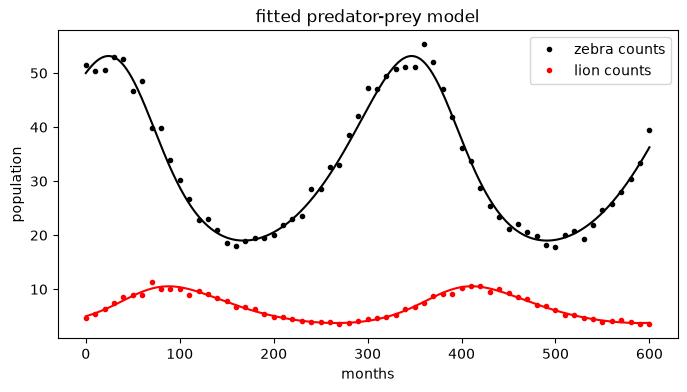

In [13]:
fine_t = np.linspace(0, 600, 600)
fitted = solve_ivp(lions_zebras, (0, 600), y0, t_eval=fine_t, args=tuple(fit.x),
                   rtol=1e-8, atol=1e-8).y

plt.figure(figsize=(8, 4))
plt.plot(t_obs, counts[1], 'k.', label='zebra counts')
plt.plot(t_obs, counts[0], 'r.', label='lion counts')
plt.plot(fine_t, fitted[1], 'k')
plt.plot(fine_t, fitted[0], 'r')
plt.xlabel('months')
plt.ylabel('population')
plt.legend()
plt.title('fitted predator-prey model')
plt.show()

The estimates agree with the true rates to within one or two estimated standard
deviations.

Nonlinear least squares problems are not convex, though, and the answer can depend on where
you start:

In [14]:
bad = least_squares(count_residuals, [0.01, 0.5, 0.01], x_scale='jac')
print("start (0.01, 0.5, 0.01) ->", bad.x, f"  cost {bad.cost:.0f} vs {fit.cost:.0f} for the good fit")

start (0.01, 0.5, 0.01) -> [-0.00059541  0.02771951  0.00188658]   cost 3622 vs 50 for the good fit


That run converged, in the sense that the optimizer stopped at a point where the gradient
is small, to parameters that make no biological sense (a negative birth rate), with a much
larger cost.  Use what you know about the problem to choose starting points, try several,
and compare the costs.  The global methods in [Optimization in SciPy](scipy_opt.ipynb)
are another option for small problems.

## Stochastic gradient descent

In statistics and machine learning the objective is usually an average over a data set,

$$ f(\theta) = \frac{1}{n}\sum_{i=1}^n f_i(\theta), $$

for example $f_i(\theta) = \tfrac12 (x_i^\top\theta - y_i)^2$ for least squares.  One
gradient evaluation costs a pass over all $n$ data points.  **Stochastic gradient descent
(SGD)** instead estimates the gradient from a random **mini-batch** $B$ of the data,

$$ g_k = \frac{1}{|B|} \sum_{i \in B} \nabla f_i(\theta_k), $$

which is correct on average and far cheaper.  SGD takes many cheap, noisy steps instead of
a few expensive, accurate ones.  Performance is measured in **epochs**, the number of passes
through the data.

Here is a linear regression with $n = 10{,}000$ observations of $p = 20$ features of very
different scales, so that the problem has condition number about 100.

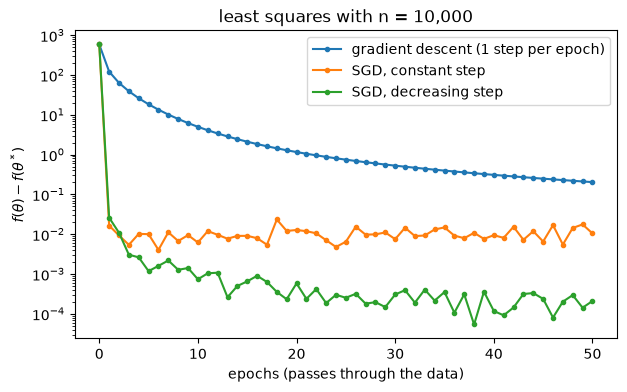

In [15]:
n, p = 10_000, 20
X = rng.standard_normal((n, p)) * np.linspace(1, 10, p)
y = X @ rng.standard_normal(p) + 0.5 * rng.standard_normal(n)

loss = lambda th: 0.5 * np.mean((X @ th - y)**2)
th_star, *_ = np.linalg.lstsq(X, y, rcond=None)
loss_star = loss(th_star)
L = np.linalg.eigvalsh(X.T @ X / n).max()


def full_gradient_descent(epochs):
    th = np.zeros(p)
    gaps = [loss(th) - loss_star]
    for _ in range(epochs):
        th = th - (X.T @ (X @ th - y) / n) / L
        gaps.append(loss(th) - loss_star)
    return np.array(gaps)


def sgd(epochs, batch=32, lr=0.5 / L, decay=False):
    th = np.zeros(p)
    gaps = [loss(th) - loss_star]
    steps_per_epoch = n // batch
    k = 0
    for _ in range(epochs):
        order = rng.permutation(n)
        for j in range(steps_per_epoch):
            idx = order[j * batch:(j + 1) * batch]
            g = X[idx].T @ (X[idx] @ th - y[idx]) / batch
            step = lr / (1 + k / (2 * steps_per_epoch)) if decay else lr
            th = th - step * g
            k += 1
        gaps.append(loss(th) - loss_star)
    return np.array(gaps)


epochs = 50
plt.figure(figsize=(7, 4))
plt.semilogy(full_gradient_descent(epochs), 'o-', ms=3, label='gradient descent (1 step per epoch)')
plt.semilogy(sgd(epochs), 'o-', ms=3, label='SGD, constant step')
plt.semilogy(sgd(epochs, decay=True), 'o-', ms=3, label='SGD, decreasing step')
plt.xlabel('epochs (passes through the data)')
plt.ylabel(r'$f(\theta) - f(\theta^*)$')
plt.legend()
plt.title('least squares with n = 10,000')
plt.show()

After one pass through the data, SGD has taken about 300 steps while gradient descent has
taken one, and SGD is far ahead.  With a constant step, SGD then stalls at a level set by
the gradient noise: the steps never get small enough to settle down.  Decreasing the step
size over time removes the floor.

Here the exact answer is one call to `lstsq` away, so SGD is just a demonstration.  It
becomes the method of choice when $n$ is huge, the model is not linear, and an
approximate minimizer is good enough, which describes training neural networks
([PyTorch Neural Networks](../08_data/pytorch.ipynb)).

## Which method?

| situation | method |
|:--|:--|
| smooth, small or medium $n$, gradient available | `BFGS` (the default in `minimize`) |
| large $n$, or simple bounds on the variables | `L-BFGS-B` |
| Hessian (or Hessian-vector products) available | `trust-exact`, `trust-ncg`, `Newton-CG` |
| no derivatives, few variables | `Nelder-Mead`, `Powell` |
| sum of squares, fitting a model to data | `least_squares`, `curve_fit` |
| average over a huge data set | SGD or Adam (for example in PyTorch) |
| many local minima, few variables | `basinhopping`, `differential_evolution` |

Whatever the method, provide derivatives when you can (by hand, or with automatic
differentiation as in PyTorch), scale the variables so they have comparable sizes, and
check the result from more than one starting point.

## Exercises

### Exercise 1

For the quadratic $f(x) = \tfrac12 x^\top A x$, the step length that exactly minimizes $f$
along the direction $-g$ is $\alpha = g^\top g / g^\top A g$.  Derive this, implement
gradient descent with this **exact line search**, and plot its path for $\kappa = 30$.
Show numerically that consecutive steps are orthogonal.  Is it faster than the best fixed
step?

In [16]:
# Your code here

### Exercise 2

Apply pure Newton's method (no line search) to $f(x) = \sqrt{1 + x^2}$, whose minimum is at
$x = 0$, starting from $x_0 = 0.5$, $0.9$, and $1.1$.  Show that the Newton iteration is
$x_{k+1} = -x_k^3$.  For which starting points does it converge, and how fast?  Then add
the backtracking line search and try $x_0 = 10$.

In [17]:
# Your code here

### Exercise 3

Compare `BFGS`, `L-BFGS-B`, and `CG` on the $n$-dimensional Rosenbrock function (`rosen`
accepts vectors of any length) for $n = 10, 100, 1000$, starting from zero.  Record
iterations, function evaluations, and time.  How does each scale with $n$, and why?

In [18]:
# Your code here

### Exercise 4

Fit a Gaussian peak $a\, e^{-(t - c)^2 / (2w^2)}$ to noisy data generated with $a = 1$,
$c = 0$, $w = 0.5$ on $t \in [-3, 3]$.  Run Gauss-Newton and Levenberg-Marquardt from a
grid of starting values of $c$ between $-3$ and $3$ (keep $a = 1$, $w = 1$), and plot which
starting points converge to the right answer for each method.

In [19]:
# Your code here

### Exercise 5

Repeat the SGD experiment with batch sizes 1, 32, and 1024 (adjust the step size so each
is stable).  Plot the loss gap against epochs and against wall-clock time.  Which batch
size is best by each measure?

In [20]:
# Your code here